# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: Gate 2 = GO / Gate 3 = NA → non-branching, so the branching-only
`04_correlation` and `05_modules` notebooks are **not** produced. This unconditional EMT-TF
notebook follows signatures directly and is the last notebook.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the derive-don't-inherit mandate
we do not inherit that pair: we score a candidate EMT-TF panel — the canonical **Snail/Zeb/Twist**
factors **plus the mesenchymal/neural-crest FOXC and PRRX families** (the Kürten lesson) — along
*this* trajectory and let the data pick the most end-specific factor at each end. Factors below a
detection floor are too sparse to overlay. (VIM is a mesenchymal marker, not a TF, and is excluded.)
Deliverable: `expression.pdf`.

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold (house linear layout)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 360 | pseudotime range 0.0 -> 6.79


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in early (root) vs late
(terminus) pseudotime terciles, and Spearman correlation with pseudotime. The most negative
correlation (sufficiently expressed) marks the root end, the most positive the terminus. A 3%
expression floor removes factors too sparse to overlay.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel present:', present)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX2      0.011       0.029      0.050     0.079 LATE(terminus)
 SNAI1      0.044       0.123      0.234     0.112 LATE(terminus)
TWIST2      0.011       0.000      0.074     0.113 LATE(terminus)
TWIST1      0.036       0.026      0.119     0.115 LATE(terminus)
 PRRX1      0.056       0.126      0.234     0.133 LATE(terminus)
  ZEB1      0.039       0.059      0.154     0.143 LATE(terminus)
  ZEB2      0.050       0.009      0.215     0.193 LATE(terminus)
 SNAI2      0.075       0.043      0.541     0.217 LATE(terminus)
 FOXC1      0.333       0.625      1.560     0.259 LATE(terminus)

derived pair: SNAI1 (early/root) <-> FOXC1 (late/terminus)


### EMT-TF expression overlay (deliverable `expression.pdf`)
House style: `figsize=(3.5,1.5)`, `size=30`, categorical overlay of thresholded expressers on a grey
manifold (**not** a continuous colormap — Sun-2021 lesson). Each factor is thresholded at the upper
quartile among its expressers so only the strongest show and root (blue) / terminus (red) separate;
the abundant marker is drawn first so the sparser one reads on top.

SNAI1: 4.4% expressing; 4 shown (upper quartile), mean pseudotime of shown = 0.34 (all = 0.51)
FOXC1: 33.3% expressing; 30 shown (upper quartile), mean pseudotime of shown = 0.57 (all = 0.51)
shown-cell pseudotime separation (SNAI1 vs FOXC1) = 0.24
saved expression.pdf


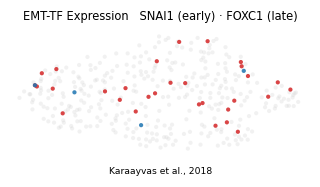

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {abs(tn[sel[late_tf]].mean()-tn[sel[early_tf]].mean()):.2f}')
print('saved expression.pdf')